In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 8.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
!git clone --depth 1 https://github.com/Shenggan/BCCD_Dataset.git

Cloning into 'BCCD_Dataset'...
remote: Enumerating objects: 753, done.
remote: Counting objects: 100% (753/753), done.
remote: Compressing objects: 100% (391/391), done.
remote: Total 753 (delta 361), reused 746 (delta 359), pack-reused 0 (from 0)
Receiving objects: 100% (753/753), 7.37 MiB | 12.66 MiB/s, done.
Resolving deltas: 100% (361/361), done.


In [35]:
### Ultralytics provides the YOLO implementation, training pipeline, validation, and prediction tools.

import os

base_path = "/content/BCCD_Dataset/BCCD"

print(os.listdir(base_path))
print("Images:", len(os.listdir(f"{base_path}/JPEGImages")))
print("Annotations:", len(os.listdir(f"{base_path}/Annotations")))

['Annotations', 'JPEGImages', 'ImageSets']
Images: 364
Annotations: 364


##Convert Pascal VOC to YOLO format

YOLO requires a different annotation format.
---
For each object, YOLO expects: `class_id x_center y_center width height`


Conversion formula:

$
x_c = \frac{x_{\min}+x_{\max}}{2W}
$

$
y_c = \frac{y_{\min}+y_{\max}}{2H}
$

$
w = \frac{x_{\max}-x_{\min}}{W}
$

$
h = \frac{y_{\max}-y_{\min}}{H}
$

Here $W, H$ represent image width and height.

In [36]:
classes = {
    "RBC": 0,
    "WBC": 1,
    "Platelets": 2
}

In [37]:
import os
import random
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path

random.seed(42)

source = Path("/content/BCCD_Dataset/BCCD")
output = Path("/content/BCCD_YOLO")

classes = {"RBC": 0, "WBC": 1, "Platelets": 2}

images = sorted((source / "JPEGImages").glob("*.jpg"))

random.shuffle(images)

n = len(images)
train_end = int(n * 0.7)
val_end = int(n * 0.9)

splits = {
    "train": images[:train_end],
    "val": images[train_end:val_end],
    "test": images[val_end:]
}

for split, files in splits.items():

    img_dir = output / "images" / split
    label_dir = output / "labels" / split

    img_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for img_path in files:

        xml_path = source / "Annotations" / (img_path.stem + ".xml")

        tree = ET.parse(xml_path)
        root = tree.getroot()

        width = float(root.find("size/width").text)
        height = float(root.find("size/height").text)

        labels = []

        for obj in root.findall("object"):

            name = obj.find("name").text

            if name not in classes:
                continue

            box = obj.find("bndbox")

            xmin = float(box.find("xmin").text)
            ymin = float(box.find("ymin").text)
            xmax = float(box.find("xmax").text)
            ymax = float(box.find("ymax").text)

            xc = ((xmin + xmax) / 2) / width
            yc = ((ymin + ymax) / 2) / height
            w = (xmax - xmin) / width
            h = (ymax - ymin) / height

            labels.append(
                f"{classes[name]} {xc} {yc} {w} {h}"
            )

        shutil.copy(img_path, img_dir / img_path.name)

        label_path = label_dir / (img_path.stem + ".txt")
        label_path.write_text("\n".join(labels))

print("Dataset conversion completed!")

for split, files in splits.items():
    proportion = (len(files) / n) * 100
    print(f"{split}: {len(files)} ({proportion:.1f}%)")

Dataset conversion completed!
train: 254 (69.8%)
val: 73 (20.1%)
test: 37 (10.2%)


### Create YOLO configuration

In [38]:
yaml_content = """
path: /content/BCCD_YOLO

train: images/train
val: images/val
test: images/test

names:
  0: RBC
  1: WBC
  2: Platelets
"""

with open("/content/BCCD_YOLO/data.yaml", "w") as f:
    f.write(yaml_content)

### Visualize ground-truth annotations

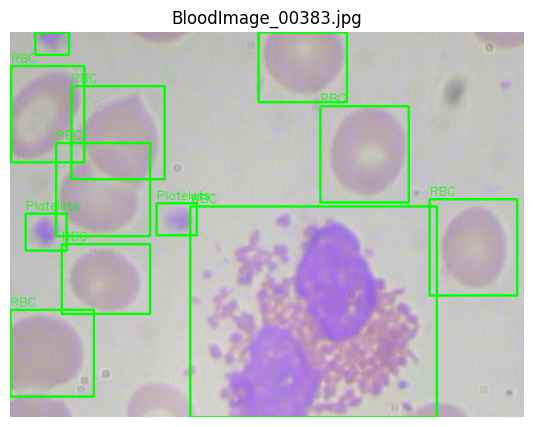

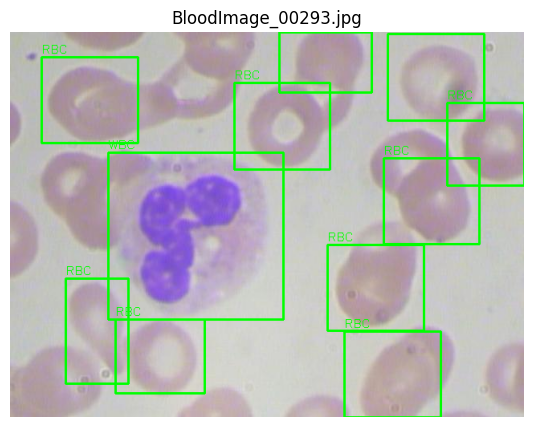

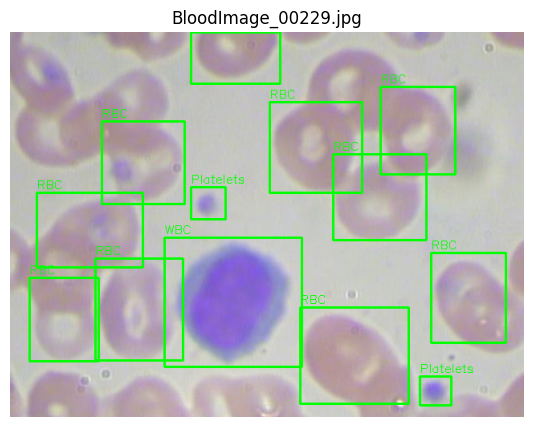

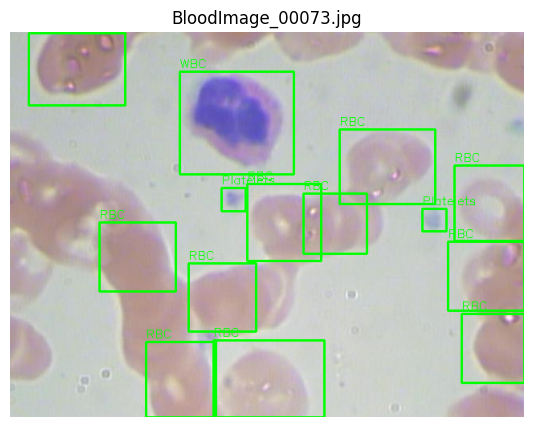

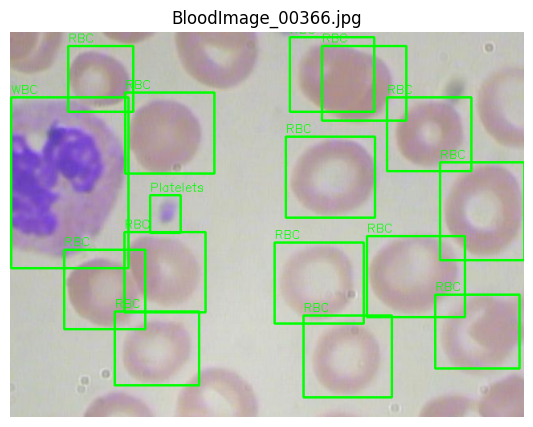

In [39]:
import cv2
import matplotlib.pyplot as plt
import random

class_names = ["RBC", "WBC", "Platelets"]

image_files = list(
    Path("/content/BCCD_YOLO/images/train").glob("*.jpg")
)

selected = random.sample(image_files, 5)

for image_path in selected:

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    label_path = Path(
        "/content/BCCD_YOLO/labels/train"
    ) / (image_path.stem + ".txt")

    H, W = image.shape[:2]

    for line in label_path.read_text().splitlines():

        cls, xc, yc, w, h = map(float, line.split())

        x1 = int((xc - w/2) * W)
        y1 = int((yc - h/2) * H)
        x2 = int((xc + w/2) * W)
        y2 = int((yc + h/2) * H)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

        cv2.putText(
            image,
            class_names[int(cls)],
            (x1, y1 - 5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1
        )

    plt.figure(figsize=(8, 5))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

## 2 Baseline model training

In [15]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Train the baseline

In [16]:
import time

start_time = time.time()

results = model.train(
    data="/content/BCCD_YOLO/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    lr0=0.01,
    seed=42,
    device=0,
    project="/content/BCCD_Results",
    name="baseline",
    patience=15,
    plots=True
)

training_time = time.time() - start_time

print(f"Training time: {training_time / 60:.2f} minutes")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BCCD_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, opti

In [18]:
import torch

checkpoint = torch.load(
    "/content/BCCD_Results/baseline/weights/best.pt",
    map_location="cpu",
    weights_only=False
)

print(checkpoint.keys())

dict_keys(['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'stopper', 'model', 'ema', 'updates', 'modelopt', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git'])


### 3 prediction examples

In [40]:
from ultralytics import YOLO

model = YOLO("/content/BCCD_Results/baseline/weights/best.pt")

results = model.predict(
    source="/content/BCCD_YOLO/images/test",
    conf=0.25,
    save=True
)


image 1/37 /content/BCCD_YOLO/images/test/BloodImage_00003.jpg: 480x640 23 RBCs, 1 WBC, 3 Plateletss, 7.8ms
image 2/37 /content/BCCD_YOLO/images/test/BloodImage_00012.jpg: 480x640 20 RBCs, 1 WBC, 2 Plateletss, 9.2ms
image 3/37 /content/BCCD_YOLO/images/test/BloodImage_00013.jpg: 480x640 21 RBCs, 1 WBC, 9.1ms
image 4/37 /content/BCCD_YOLO/images/test/BloodImage_00015.jpg: 480x640 16 RBCs, 1 WBC, 2 Plateletss, 9.1ms
image 5/37 /content/BCCD_YOLO/images/test/BloodImage_00016.jpg: 480x640 17 RBCs, 1 WBC, 1 Platelets, 8.8ms
image 6/37 /content/BCCD_YOLO/images/test/BloodImage_00046.jpg: 480x640 19 RBCs, 1 WBC, 1 Platelets, 9.3ms
image 7/37 /content/BCCD_YOLO/images/test/BloodImage_00049.jpg: 480x640 13 RBCs, 1 WBC, 1 Platelets, 9.4ms
image 8/37 /content/BCCD_YOLO/images/test/BloodImage_00055.jpg: 480x640 10 RBCs, 1 WBC, 4 Plateletss, 8.6ms
image 9/37 /content/BCCD_YOLO/images/test/BloodImage_00062.jpg: 480x640 14 RBCs, 1 WBC, 1 Platelets, 9.8ms
image 10/37 /content/BCCD_YOLO/images/test/Bl

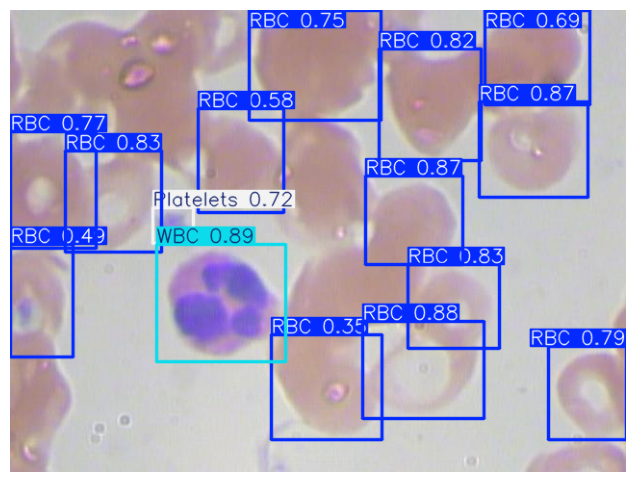

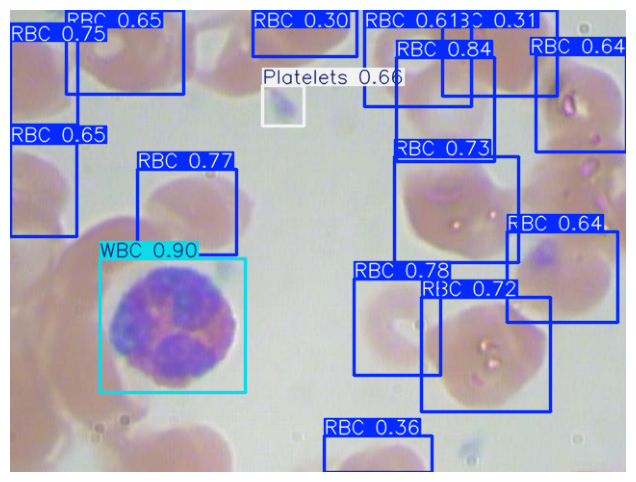

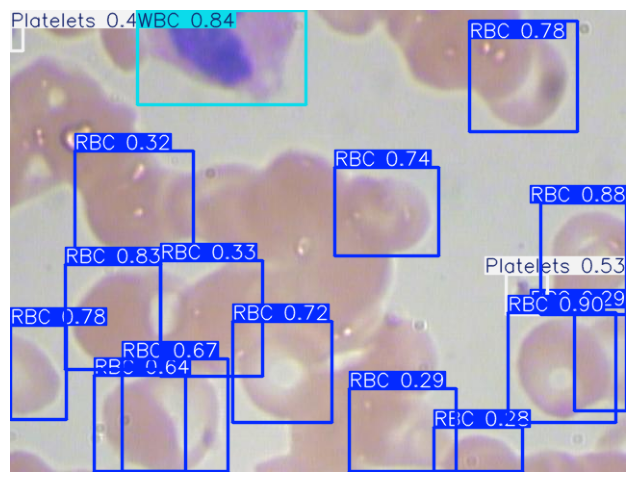

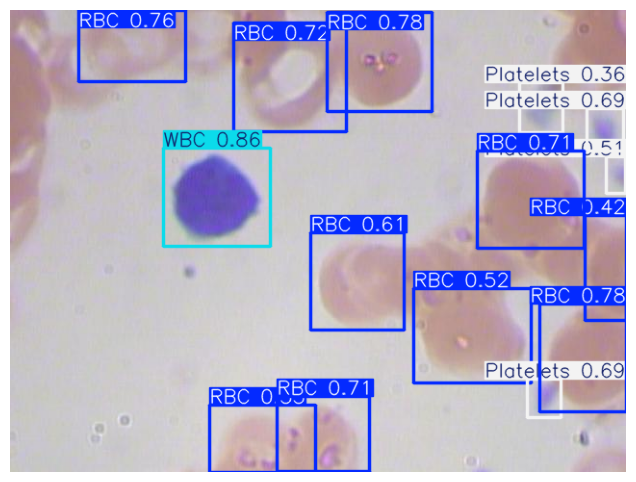

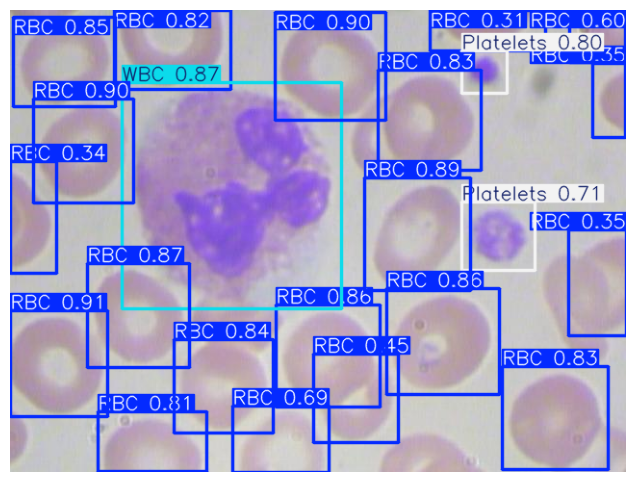

In [41]:
import random
import matplotlib.pyplot as plt

selected = random.sample(results, 5)

for result in selected:
    image = result.plot()

    plt.figure(figsize=(10, 6))
    plt.imshow(image[:, :, ::-1])
    plt.axis("off")
    plt.show()

## 3 — Controlled experiment
Objective: Train a second model while changing exactly one parameter. Compare it with your baseline.

3.1 Experiment hypothesis
For this experiment, let's change the image size:
- Baseline: imgsz=640
- Experiment: imgsz=512

Hypothesis: Reducing image size to 512 may decrease training time while maintaining reasonably similar detection performance. However, smaller objects such as platelets may become harder to detect.

|Parameter|	Baseline|	Experiment|
|---|---|---|
|Model	| YOLO11n| 	YOLO11n
|Initial weights| 	yolo11n.pt	|yolo11n.pt
|Image size	| 640	| 512
|Epochs	| 50	| 50
|Batch size	| 8	| 8
|Learning rate| 	0.01| 	0.01
|Seed	| 42	| 42
|Dataset split| 	70/20/10	| 70/20/10

Train the experimental model

In [24]:

from ultralytics import YOLO
import time

# Load the same pretrained checkpoint
model = YOLO("yolo11n.pt")

start_time = time.time()

# Train with only image size changed
results = model.train(
    data="/content/BCCD_YOLO/data.yaml",
    epochs=50,
    imgsz=512,
    batch=8,
    lr0=0.01,
    seed=42,
    device=0,
    patience=15,
    plots=True,
    project="/content/BCCD_Results",
    name="experiment_512"
)

training_time = (time.time() - start_time) / 60

print(f"Experiment training time: {training_time:.2f} minutes")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BCCD_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_512, nbs=64, nms=None, opset=None, optimize=False

In [26]:
### Compare the two models

from ultralytics import YOLO

# Baseline
baseline = YOLO(
    "/content/BCCD_Results/baseline/weights/best.pt"
)

baseline_metrics = baseline.val(
    data="/content/BCCD_YOLO/data.yaml",
    split="val",
    imgsz=640
)

# Experiment
experiment = YOLO(
    "/content/BCCD_Results/experiment_512/weights/best.pt"
)

experiment_metrics = experiment.val(
    data="/content/BCCD_YOLO/data.yaml",
    split="val",
    imgsz=512
)

print("Baseline mAP50:", baseline_metrics.box.map50)
print("Experiment mAP50:", experiment_metrics.box.map50)

print("Baseline mAP50-95:", baseline_metrics.box.map)
print("Experiment mAP50-95:", experiment_metrics.box.map)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 930.9±304.4 MB/s, size: 20.0 KB)
val: Scanning /content/BCCD_YOLO/labels/val.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 23.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.2it/s 2.3s
                   all         73        972      0.867      0.875       0.93      0.641
                   RBC         68        826      0.847      0.759      0.896       0.64
                   WBC         72         72       0.98          1      0.983      0.785
             Platelets         39         74      0.772      0.865      0.912      0.498
Speed: 4.3ms preprocess, 7.5ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to /content/runs/detect/val
Ultralytics 8.4.

In [27]:
print("=== BASELINE ===")
print("Precision:", baseline_metrics.box.mp)
print("Recall:", baseline_metrics.box.mr)

print("\n=== EXPERIMENT ===")
print("Precision:", experiment_metrics.box.mp)
print("Recall:", experiment_metrics.box.mr)

=== BASELINE ===
Precision: 0.8666391125081131
Recall: 0.8746207732491295

=== EXPERIMENT ===
Precision: 0.8781818309296678
Recall: 0.8544052527103374


| Metric | Baseline (640px)	|Experiment (512px) |	Difference|
|---|---|---|---|
|Precision |	0.8666|	0.8782	|+0.0115
|Recall	|0.8746|	0.8544	|-0.0202
|mAP@0.50|	0.9303|	0.9229|	-0.0074
|mAP@0.50:0.95|	0.6409	|0.6305	|-0.0105
|Training time|	4.95 min|	3.53 min|	-28.7%

1. Precision increased: The 512px model has slightly fewer false-positive detections relative to its predicted objects.

2. Recall decreased: The 640px model detects a larger proportion of actual objects.

3. Detection quality: Both mAP metrics are slightly higher for the baseline.

4. Efficiency: Reducing image size from 640px to 512px reduced training time by approximately 28.7%.
____

*The baseline provides better overall detection performance, particularly in recall and mAP. The experiment demonstrates that smaller image sizes can improve computational efficiency, but may slightly reduce detection quality.*

## 4 - Final evaluation

Objective: Evaluate the final model on previously unseen test images and analyze its detection performance.

4.1 Load the final model

In [28]:

from ultralytics import YOLO

# Load the selected baseline model
final_model = YOLO(
    "/content/BCCD_Results/baseline/weights/best.pt"
)

print("Final model loaded successfully!")


Final model loaded successfully!


4.2 — Evaluate on the test dataset

In [29]:

test_metrics = final_model.val(
    data="/content/BCCD_YOLO/data.yaml",
    split="test",
    imgsz=640,
    conf=0.001,
    iou=0.7,
    plots=True,
    save_json=True,
    project="/content/BCCD_Results",
    name="final_test"
)

print("\n===== FINAL TEST RESULTS =====")
print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP@0.50:", test_metrics.box.map50)
print("mAP@0.50:0.95:", test_metrics.box.map)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 780.9±325.3 MB/s, size: 19.7 KB)
val: Scanning /content/BCCD_YOLO/labels/test... 37 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 37/37 1.3Kit/s 0.0s
val: New cache created: /content/BCCD_YOLO/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.7s
                   all         37        498      0.842      0.909      0.933       0.65
                   RBC         37        426      0.796      0.833      0.913       0.64
                   WBC         36         37      0.952          1      0.994      0.787
             Platelets         22         35      0.777      0.894      0.893      0.522
Speed: 5.1ms preprocess, 8.1ms inference, 0.0ms loss, 2.9ms postprocess per image
Sav

4.3 - Generate five prediction examples

In [30]:

prediction_results = final_model.predict(
    source="/content/BCCD_YOLO/images/test",
    conf=0.25,
    imgsz=640,
    save=True,
    project="/content/BCCD_Results",
    name="test_predictions"
)

print("Number of test images:", len(prediction_results))



image 1/37 /content/BCCD_YOLO/images/test/BloodImage_00003.jpg: 480x640 23 RBCs, 1 WBC, 3 Plateletss, 8.0ms
image 2/37 /content/BCCD_YOLO/images/test/BloodImage_00012.jpg: 480x640 20 RBCs, 1 WBC, 2 Plateletss, 9.5ms
image 3/37 /content/BCCD_YOLO/images/test/BloodImage_00013.jpg: 480x640 21 RBCs, 1 WBC, 9.2ms
image 4/37 /content/BCCD_YOLO/images/test/BloodImage_00015.jpg: 480x640 16 RBCs, 1 WBC, 2 Plateletss, 16.9ms
image 5/37 /content/BCCD_YOLO/images/test/BloodImage_00016.jpg: 480x640 17 RBCs, 1 WBC, 1 Platelets, 22.8ms
image 6/37 /content/BCCD_YOLO/images/test/BloodImage_00046.jpg: 480x640 19 RBCs, 1 WBC, 1 Platelets, 26.5ms
image 7/37 /content/BCCD_YOLO/images/test/BloodImage_00049.jpg: 480x640 13 RBCs, 1 WBC, 1 Platelets, 22.5ms
image 8/37 /content/BCCD_YOLO/images/test/BloodImage_00055.jpg: 480x640 10 RBCs, 1 WBC, 4 Plateletss, 15.5ms
image 9/37 /content/BCCD_YOLO/images/test/BloodImage_00062.jpg: 480x640 14 RBCs, 1 WBC, 1 Platelets, 19.4ms
image 10/37 /content/BCCD_YOLO/images/t

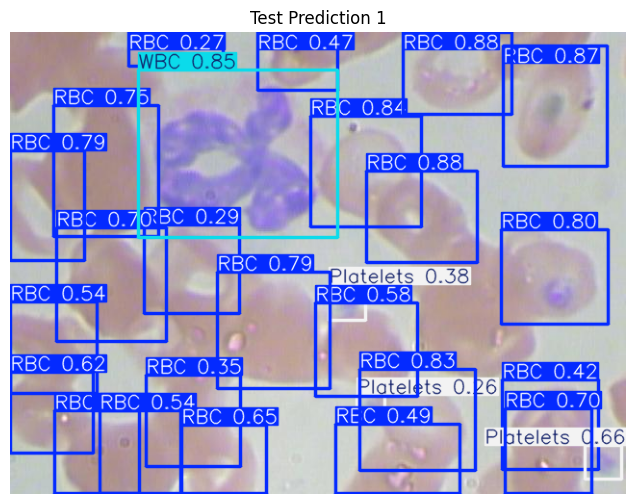

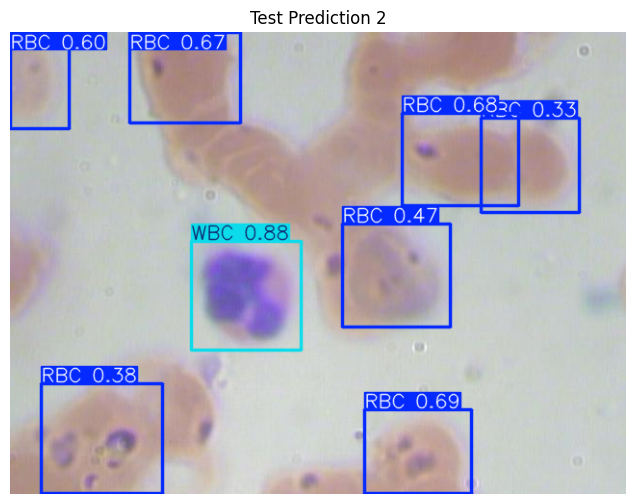

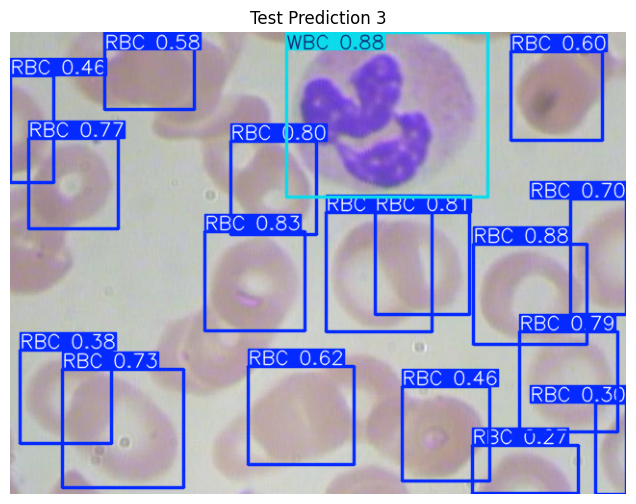

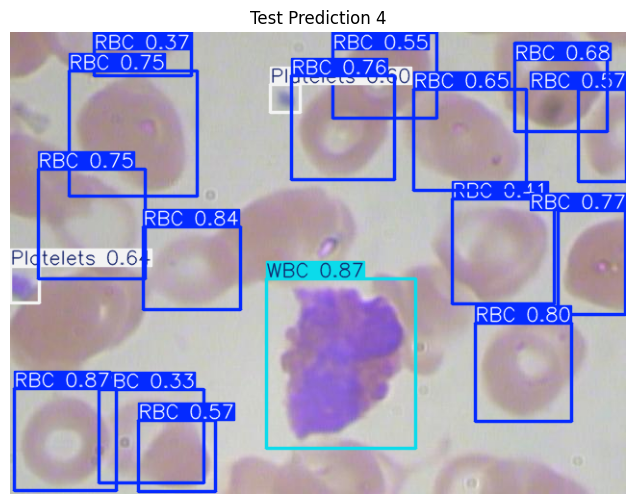

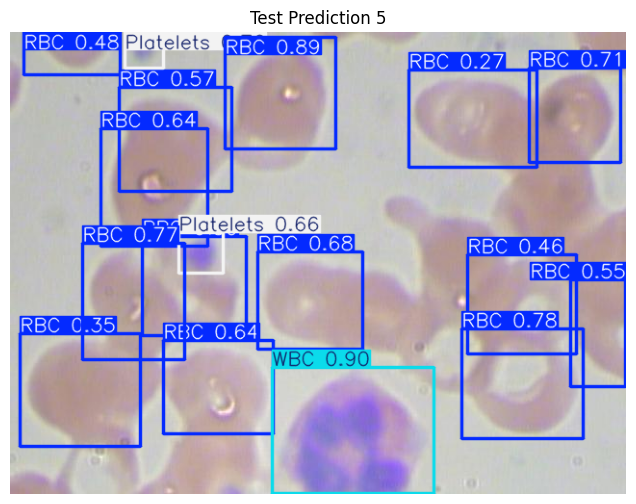

In [31]:

import matplotlib.pyplot as plt
import random

selected = random.sample(
    prediction_results,
    min(5, len(prediction_results))
)

for i, result in enumerate(selected, 1):
    image = result.plot()

    plt.figure(figsize=(10, 6))
    plt.imshow(image[:, :, ::-1])
    plt.title(f"Test Prediction {i}")
    plt.axis("off")
    plt.show()


1. Small and Faint Objects: Missed Platelets (False Negatives)
-  **What happened:** In Test Prediction 1 (bottom right) and Test Prediction 4 (top middle/left), several small, faint purple spots representing Platelets are either completely missed by the model or detected with very low confidence (e.g., Platelets with 0.26 and 0.38 confidence in Prediction 1).
- **Why it happened:** Platelets are significantly smaller than RBCs and WBCs, meaning they contain fewer features. When downsampled through deep convolutional layers, their spatial features can easily get lost, especially if they are faint.
- **How to improve:** We could utilize feature pyramid architectures (like FPN/PANet already in YOLO) with specialized small-object detection heads, or apply a slightly lower confidence threshold (conf) specifically for the Platelet class during inference.
___


2. Clustered and Overlapping Cells: Under-segmentation / Overlapping RBCs (False Negatives)
- **What happened:** In Test Prediction 3 (bottom-left area) and Test Prediction 5 (left edge), several Red Blood Cells (RBCs) are tightly packed and overlapping. The model only detects a few of them, leaving others in the cluster without bounding boxes.
- **Why it happened:** When cells overlap heavily, their boundaries merge. The Non-Maximum Suppression (NMS) step might also suppress nearby overlapping bounding boxes if their Intersection over Union (IoU) exceeds the NMS threshold, treating them as duplicate detections of the same cell.
- **How to improve:** We can train the model with heavier augmentation techniques such as MixUp or Mosaic to help it learn partial occlusions, or slightly tune the IoU threshold during inference to allow closely packed boxes.
____

3. Edge/Border Effects: Truncated Cells (Localization Errors)
- **What happened:** In Test Prediction 1 (top left and bottom left) and Test Prediction 5 (top left edge), cells that are partially cut off by the border of the image are either poorly localized with low-confidence bounding boxes or completely ignored.
- **Why it happened:** Partially visible cells lack their complete shape features (e.g., an RBC loses its circular symmetry at the border), making them look different from the fully visible cells in the training distribution.
- **How to improve:** Applying random cropping and translation during the training augmentation phase will force the network to learn to identify cells even when only a fraction of them is visible.

In [44]:
from google.colab import files

files.download("BCCD_Results/baseline/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
import shutil

shutil.make_archive(
    "/content/BCCD_Project_Results",
    "zip",
    "/content/BCCD_Results"
)

files.download("/content/BCCD_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:

import sys
import torch
import ultralytics
import torchvision
import numpy
import pandas
import matplotlib

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Ultralytics:", ultralytics.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Ultralytics: 8.4.216
NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0
CUDA available: True
GPU: Tesla T4
